In [ ]:
import numpy as np  # linear algebra
import pandas as pd  # data processing, CSV file I/O (e.g. pd.read_csv)

Load data

In [ ]:
df = pd.read_csv('/content/amazon_reviews.csv')

df = df.sample(n=15000, random_state=42)

In [ ]:
df.head()

,reviewId,userName,content,score,thumbsUpCount,reviewCreatedVersion,at,appVersion
32260,02e043be-fa71-4c48-b48b-3d6693a29649,Lana Satlodge,I like Amazon. I can purchase literally everyt...,2,41,26.15.0.100,2023-11-16 14:48:56,26.15.0.100
53665,c2aab4a6-1a2f-4ea3-b6fc-0999d451c725,Cary Fabregas,This app won't let me do anything. No matter w...,4,0,26.21.0.100,2024-03-14 21:28:14,26.21.0.100
20612,686412e8-16fc-4bbf-9fa7-f270e2a5fe83,Abigail Manake,Amazon South Africa is a joke. The books I rea...,1,0,28.13.6.100,2024-07-19 13:54:58,28.13.6.100
6370,e96afb49-2f6d-4934-be2d-71c3e5ff36a3,M S,Full of fake reviews...full of fake products.....,1,1,30.3.0.100,2025-02-28 06:15:47,30.3.0.100
5718,eb94d150-baff-4218-989a-5dbd3727295d,Arthur Melin,Keeps nagging you to get prime each time you o...,1,0,30.5.0.100,2025-03-14 11:10:56,30.5.0.100


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import re

# pilih kolom yang diperlukan
df = df.loc[:, ['userName', 'content', 'score']]

df.head()


,userName,content,score
32260,Lana Satlodge,I like Amazon. I can purchase literally everyt...,2
53665,Cary Fabregas,This app won't let me do anything. No matter w...,4
20612,Abigail Manake,Amazon South Africa is a joke. The books I rea...,1
6370,M S,Full of fake reviews...full of fake products.....,1
5718,Arthur Melin,Keeps nagging you to get prime each time you o...,1


Pembersihan Data

In [ ]:
# Menghapus data yang kosong (NaN) pada kolom 'content'
df = df.dropna(subset=['content'])

# Menghapus duplikasi berdasarkan kolom 'content'
df = df.drop_duplicates(subset=['content'])

def clean_text(text):
    text = text.lower()  # Konversi teks ke huruf kecil
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Menghapus semua karakter selain huruf dan spasi
    text = re.sub(r'\s+', ' ', text)  # Menghapus spasi berlebih
    text = text.strip()  # Menghapus spasi di awal dan akhir teks
    return text

# Apply cleaning function to 'content' column
df['cleaned_content'] = df['content'].apply(clean_text)

# Menampilkan contoh data sebelum dan sesudah pembersihan teks
print("Sebelum pembersihan:")
print(df['content'].head())

print("\nSesudah pembersihan:")
print(df['cleaned_content'].head())


Sebelum pembersihan:
32260    I like Amazon. I can purchase literally everyt...
53665    This app won't let me do anything. No matter w...
20612    Amazon South Africa is a joke. The books I rea...
6370     Full of fake reviews...full of fake products.....
5718     Keeps nagging you to get prime each time you o...
Name: content, dtype: object

Sesudah pembersihan:
32260    i like amazon i can purchase literally everyth...
53665    this app wont let me do anything no matter wha...
20612    amazon south africa is a joke the books i read...
6370     full of fake reviewsfull of fake productsand w...
5718     keeps nagging you to get prime each time you o...
Name: cleaned_content, dtype: object


Tokenisasi

In [ ]:
from nltk.tokenize import word_tokenize
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# Tokenisasi teks pada kolom 'content'
def tokenize_with_punctuation(text):
    return word_tokenize(text)

df['tokens_before'] = df['cleaned_content'].apply(tokenize_with_punctuation)

# Menampilkan hasil sebelum dan sesudah tokenisasi
print("Sebelum tokenisasi:")
print(df['cleaned_content'].head())

print("\nSetelah tokenisasi:")
print(df['tokens_before'].head())

Sebelum tokenisasi:
32260    i like amazon i can purchase literally everyth...
53665    this app wont let me do anything no matter wha...
20612    amazon south africa is a joke the books i read...
6370     full of fake reviewsfull of fake productsand w...
5718     keeps nagging you to get prime each time you o...
Name: cleaned_content, dtype: object

Setelah tokenisasi:
32260    [i, like, amazon, i, can, purchase, literally,...
53665    [this, app, wont, let, me, do, anything, no, m...
20612    [amazon, south, africa, is, a, joke, the, book...
6370     [full, of, fake, reviewsfull, of, fake, produc...
5718     [keeps, nagging, you, to, get, prime, each, ti...
Name: tokens_before, dtype: object


Stop Word Removal

In [ ]:
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
# Mengunduh daftar stopwords dalam bahasa Inggris
stop_words = set(stopwords.words('english'))

# Menghapus stopwords dari tokens
df['tokens_after'] = df['tokens_before'].apply(
    lambda x: [word for word in x if word.lower() not in stop_words]
)

# Display results
print("Sebelum penghapusan stopwords:")
print(df['tokens_before'].head(10))

print("\nSetelah penghapusan stopwords:")
print(df['tokens_after'].head(10))

Sebelum penghapusan stopwords:
32260    [i, like, amazon, i, can, purchase, literally,...
53665    [this, app, wont, let, me, do, anything, no, m...
20612    [amazon, south, africa, is, a, joke, the, book...
6370     [full, of, fake, reviewsfull, of, fake, produc...
5718     [keeps, nagging, you, to, get, prime, each, ti...
67249    [best, online, shopping, store, most, secure, ...
63113    [apps, seems, to, be, working, better, but, us...
26106    [amazon, has, always, been, fair, to, me, ill,...
22803    [shopping, the, zon, is, incredible, with, the...
62554    [the, search, items, in, your, wish, list, won...
Name: tokens_before, dtype: object

Setelah penghapusan stopwords:
32260    [like, amazon, purchase, literally, everything...
53665    [app, wont, let, anything, matter, try, cant, ...
20612    [amazon, south, africa, joke, books, read, ava...
6370     [full, fake, reviewsfull, fake, productsand, t...
5718              [keeps, nagging, get, prime, time, open]
67249    [best, o

Stemmer

In [ ]:
from nltk.stem import PorterStemmer

# Inisialisasi stemmer Porter
stemmer = PorterStemmer()

# Stemming
df['tokens_after_stemming'] = df['tokens_after'].apply(
    lambda x: [stemmer.stem(word) for word in x]
)

# Menampilkan hasil sebelum dan setelah stemming
print("Sebelum stemming:")
print(df['tokens_after'].head(10))

print("\nSetelah stemming:")
print(df['tokens_after_stemming'].head(10))


Sebelum stemming:
32260    [like, amazon, purchase, literally, everything...
53665    [app, wont, let, anything, matter, try, cant, ...
20612    [amazon, south, africa, joke, books, read, ava...
6370     [full, fake, reviewsfull, fake, productsand, t...
5718              [keeps, nagging, get, prime, time, open]
67249    [best, online, shopping, store, secure, best, ...
63113    [apps, seems, working, better, using, app, nig...
26106    [amazon, always, fair, ill, always, come, back...
22803    [shopping, zon, incredible, variety, reviews, ...
62554    [search, items, wish, list, wont, allow, find,...
Name: tokens_after, dtype: object

Setelah stemming:
32260    [like, amazon, purchas, liter, everyth, amazon...
53665    [app, wont, let, anyth, matter, tri, cant, ord...
20612    [amazon, south, africa, joke, book, read, avai...
6370     [full, fake, reviewsful, fake, productsand, tr...
5718                   [keep, nag, get, prime, time, open]
67249    [best, onlin, shop, store, secur, b

Labelling

In [ ]:
!pip install afinn


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.6/52.6 kB 2.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for afinn: filename=afinn-0.1-py3-none-any.whl size=53431 sha256=22aac782f07cc2a3ad483df9c81e55c0cedff336b0975f09b4a51d40ad97f369
  Stored in directory: /root/.cache/pip/wheels/ee/d3/a0/f9255ebac29886acb1c28b35b37523f6399677fa06be379f25
Successfully built afinn


In [ ]:
from afinn import Afinn
afinn = Afinn()

# Menambahkan kolom 'sentiment_score' berdasarkan isi 'cleaned_content'
df['sentiment_score'] = df['cleaned_content'].apply(afinn.score)

# Menambahkan kolom 'sentiment' berdasarkan 'sentiment_score'
df['sentiment'] = df['sentiment_score'].apply(
    lambda score: 'Positive' if score > 0 else ('Negative' if score < 0 else 'Neutral')
)

# Menampilkan DataFrame dengan kolom 'sentiment_score' dan 'sentiment'
print(df[['cleaned_content', 'sentiment_score', 'sentiment']].head())


                                         cleaned_content  sentiment_score  \
32260  i like amazon i can purchase literally everyth...              2.0   
53665  this app wont let me do anything no matter wha...             -2.0   
20612  amazon south africa is a joke the books i read...              3.0   
6370   full of fake reviewsfull of fake productsand w...             -9.0   
5718   keeps nagging you to get prime each time you o...              0.0   

      sentiment  
32260  Positive  
53665  Negative  
20612  Positive  
6370   Negative  
5718    Neutral  


TF-IDF

In [ ]:
# TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

# Inisialisasi TfidfVectorizer
vectorizer = TfidfVectorizer()

# Terapkan TF-IDF pada kolom 'content'
X = vectorizer.fit_transform(df['cleaned_content'])

# Untuk melihat hasil TF-IDF dalam bentuk DataFrame
# Ambil fitur-fitur (kata-kata) dari vektorizer
features = vectorizer.get_feature_names_out()

# Ubah hasil TF-IDF menjadi DataFrame
tfidf_df = pd.DataFrame(X.toarray(), columns=features)

print(tfidf_df.head())


    aa  aaa  aaaaaaand  aaahhh  aamazon  aap  aas   ab  abandoned  abandoning  \
0  0.0  0.0        0.0     0.0      0.0  0.0  0.0  0.0        0.0         0.0   
1  0.0  0.0        0.0     0.0      0.0  0.0  0.0  0.0        0.0         0.0   
2  0.0  0.0        0.0     0.0      0.0  0.0  0.0  0.0        0.0         0.0   
3  0.0  0.0        0.0     0.0      0.0  0.0  0.0  0.0        0.0         0.0   
4  0.0  0.0        0.0     0.0      0.0  0.0  0.0  0.0        0.0         0.0   

   ...  zooming  zooms  zum  zuppa  zurck  zwrocie  zwrotu  zwrotw   zx  zzz  
0  ...      0.0    0.0  0.0    0.0    0.0      0.0     0.0     0.0  0.0  0.0  
1  ...      0.0    0.0  0.0    0.0    0.0      0.0     0.0     0.0  0.0  0.0  
2  ...      0.0    0.0  0.0    0.0    0.0      0.0     0.0     0.0  0.0  0.0  
3  ...      0.0    0.0  0.0    0.0    0.0      0.0     0.0     0.0  0.0  0.0  
4  ...      0.0    0.0  0.0    0.0    0.0      0.0     0.0     0.0  0.0  0.0  

[5 rows x 14896 columns]


# **Visualisasi**

Wordcloud

Positif

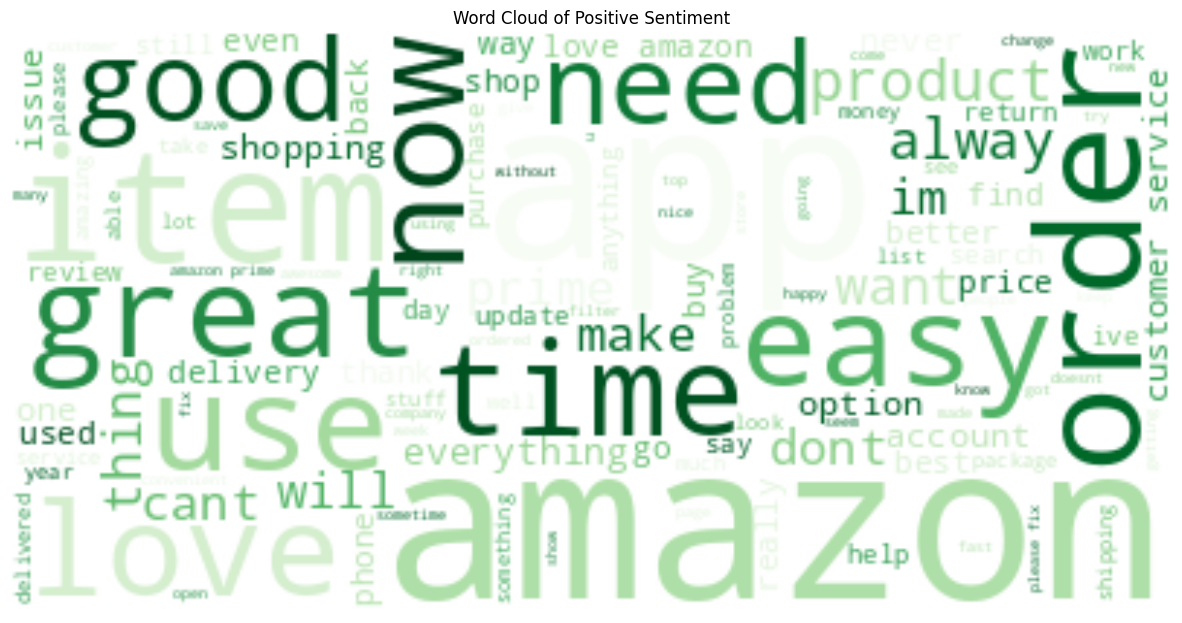

In [ ]:
from wordcloud import WordCloud
from plotly import graph_objs as go
import plotly.express as px
import plotly.figure_factory as ff
from collections import Counter
import matplotlib.pyplot as plt

df_positif = df[df['sentiment'] == 'Positive']
all_words_positif = ' '.join([twts for twts in df_positif['cleaned_content']])
wordcloud_positif = WordCloud(background_color="white", colormap="Greens").generate(all_words_positif)

plt.figure(figsize=(15, 10))
plt.imshow(wordcloud_positif, interpolation="bilinear")
plt.axis("off")
plt.title('Word Cloud of Positive Sentiment')
plt.show()


Negatif

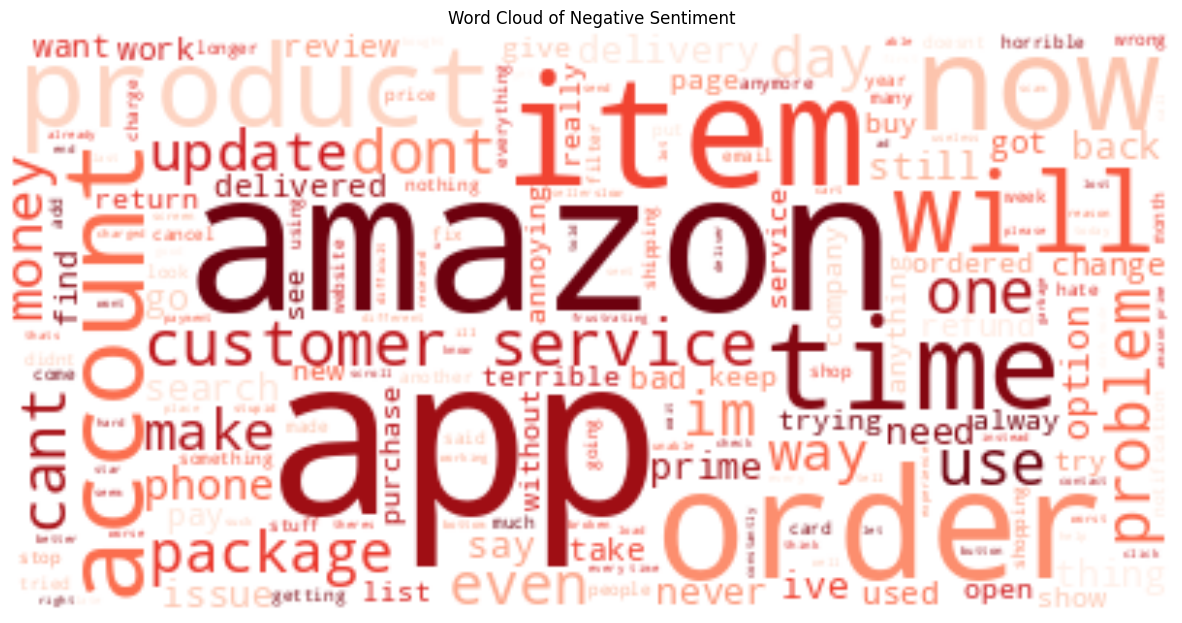

In [ ]:
df_negatif = df[df['sentiment'] == 'Negative']
all_words_negatif = ' '.join([twts for twts in df_negatif['cleaned_content']])
wordcloud_negatif = WordCloud(background_color="white", colormap="Reds").generate(all_words_negatif)

plt.figure(figsize=(15, 10))
plt.imshow(wordcloud_negatif, interpolation="bilinear")
plt.axis("off")
plt.title('Word Cloud of Negative Sentiment')
plt.show()

Neutral

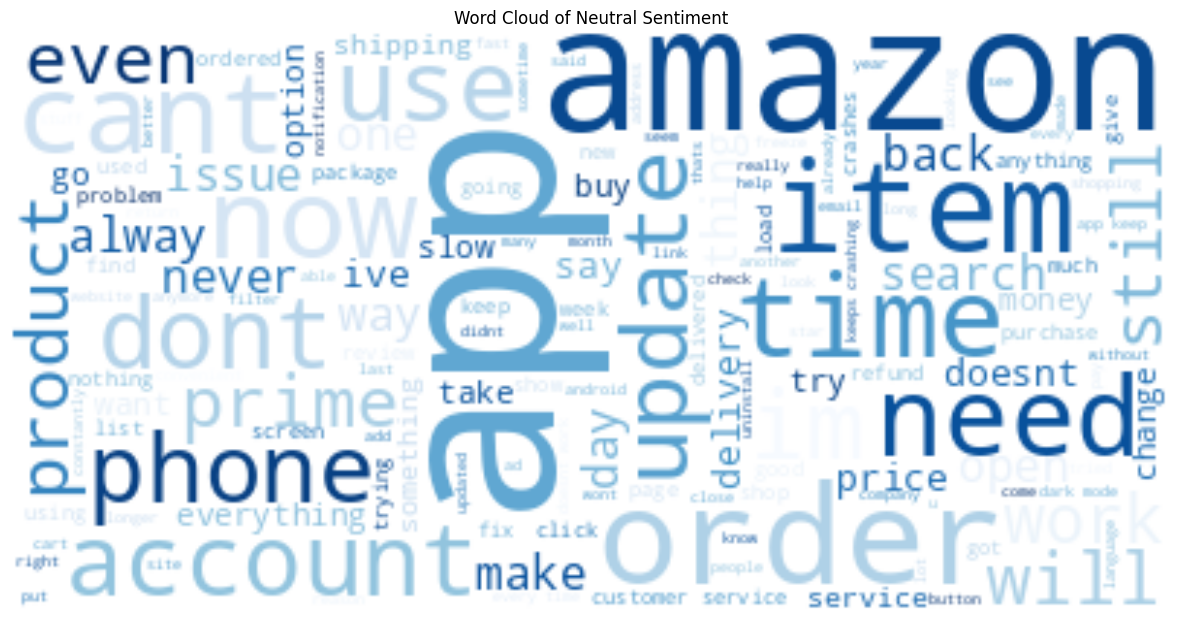

In [ ]:
df_netral = df[df['sentiment'] == 'Neutral']
all_words_netral = ' '.join([twts for twts in df_netral['cleaned_content']])
wordcloud_netral = WordCloud(background_color="white", colormap="Blues").generate(all_words_netral)

plt.figure(figsize=(15, 10))
plt.imshow(wordcloud_netral, interpolation="bilinear")
plt.axis("off")
plt.title('Word Cloud of Neutral Sentiment')
plt.show()


Funnel-Chart

In [ ]:
temp = df['sentiment'].value_counts().reset_index()
temp.columns = ['sentiment', 'count']

fig = go.Figure(go.Funnelarea(
    text=temp['sentiment'],
    values=temp['count'],
    title={"position": "top center", "text": "Funnel-Chart of Target Distribution"}
))
fig.show()

Countplot

<Axes: xlabel='sentiment', ylabel='count'>

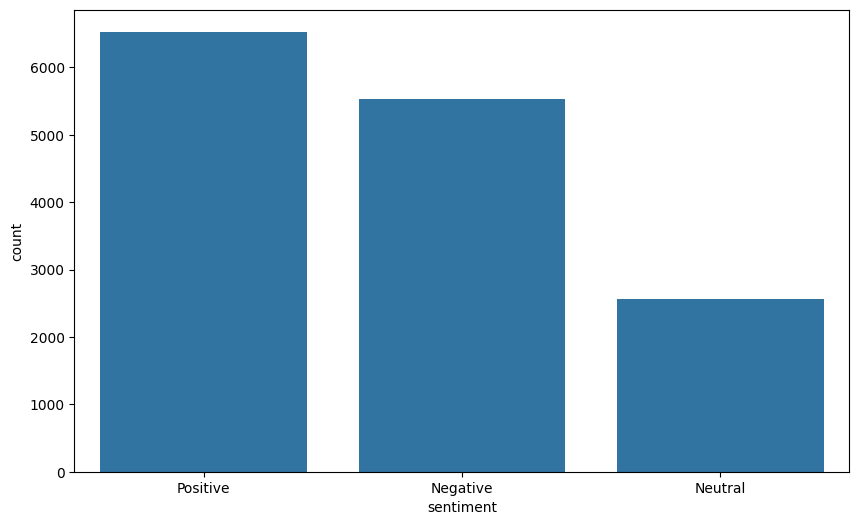

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(x='sentiment', data=df)


# **Model**

Splitting

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, df['sentiment'], test_size=0.2, random_state=42)

X_train.shape, X_test.shape


((11704, 14896), (2927, 14896))

SMOTE

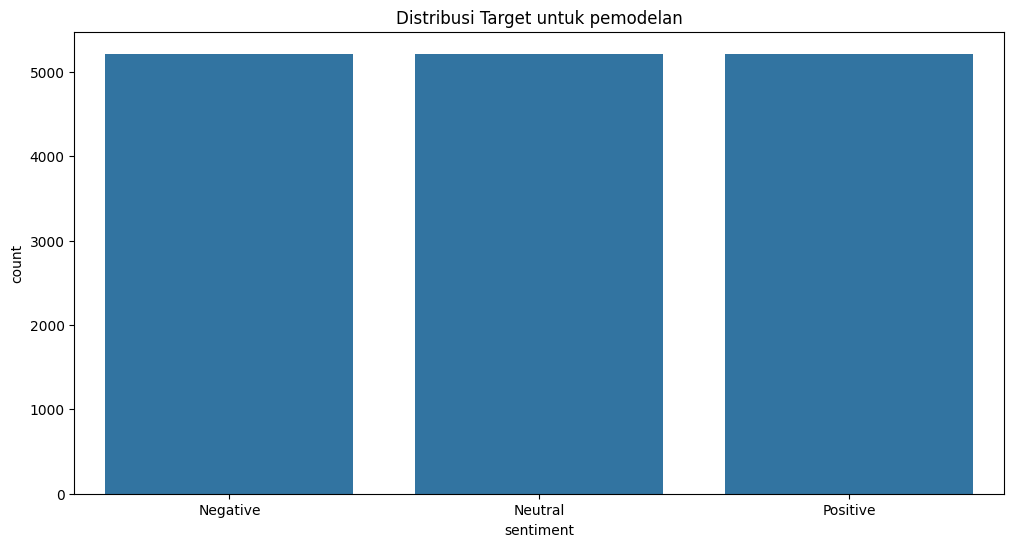

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

plt.figure(figsize=(12, 6))
sns.countplot(x=y_train)
plt.title('Distribusi Target untuk pemodelan')
plt.show()


Klasifikasi menggunakan SVM

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
# init parameters
svm_param_grid = {'C': [0.1, 1, 10],
                  'kernel': ['linear', 'rbf', 'poly'],
                  'gamma': ['scale', 'auto']}

Support Vector Machine

In [ ]:
svm_model = RandomizedSearchCV(SVC(random_state=42),
                               svm_param_grid, n_iter=10,
                               cv=5, scoring='accuracy',
                               random_state=42)
svm_model.fit(X_train, y_train)

RandomizedSearchCV(cv=5, estimator=SVC(random_state=42),
                   param_distributions={'C': [0.1, 1, 10],
                                        'gamma': ['scale', 'auto'],
                                        'kernel': ['linear', 'rbf', 'poly']},
                   random_state=42, scoring='accuracy')

In [ ]:
# print best param
print("\nBest Parameters for Support Vector Machine:", svm_model.best_params_)


Best Parameters for Support Vector Machine: {'kernel': 'linear', 'gamma': 'auto', 'C': 10}


# **Evaluasi Model**

Evaluasi Performa Validasi Silang

In [ ]:
# Evaluasi Model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

y_pred_svm = svm_model.best_estimator_.predict(X_test)

# Evaluasi performa menggunakan validasi silang
from sklearn.model_selection import cross_val_score

# Akurasi
accuracy = cross_val_score(svm_model.best_estimator_, X, df['sentiment'], cv=5, scoring='accuracy').mean()

# Presisi
precision = cross_val_score(svm_model.best_estimator_, X, df['sentiment'], cv=5, scoring='precision_weighted').mean()

# Recall
recall = cross_val_score(svm_model.best_estimator_, X, df['sentiment'], cv=5, scoring='recall_weighted').mean()

# F1 Score
f1 = cross_val_score(svm_model.best_estimator_, X, df['sentiment'], cv=5, scoring='f1_weighted').mean()

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


Accuracy: 0.8120434094522887
Precision: 0.8161707239016727
Recall: 0.8120434094522887
F1 Score: 0.8135513376370618


Confusion Matrix

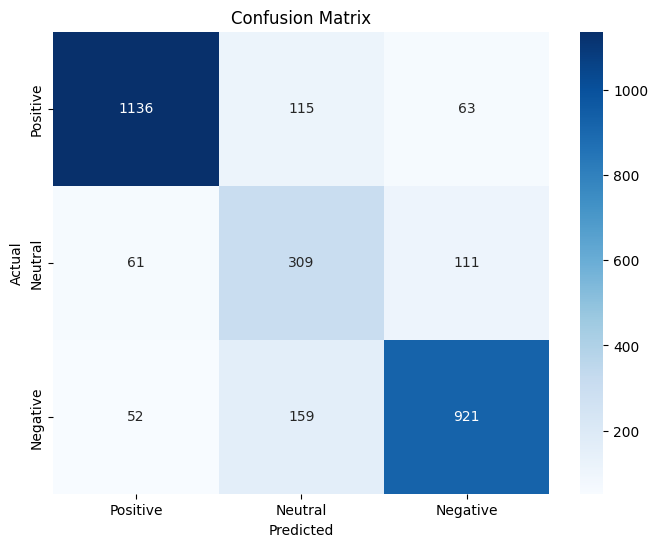

In [ ]:
# Import necessary libraries
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Menghitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred_svm, labels=['Positive', 'Neutral', 'Negative'])

# Visualisasi confusion matrix menggunakan heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Positive', 'Neutral', 'Negative'],
            yticklabels=['Positive', 'Neutral', 'Negative'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Classification Report

In [ ]:
print("\n\nClassification Report:")
print(classification_report(y_test, y_pred_svm))



Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.81      0.83      1132
     Neutral       0.53      0.64      0.58       481
    Positive       0.91      0.86      0.89      1314

    accuracy                           0.81      2927
   macro avg       0.76      0.77      0.76      2927
weighted avg       0.82      0.81      0.81      2927

